# 03 · Capture-condition gates (paper Sec. 2.2 Steps 2–4, Figs. *condition1–3*, *gate_geometry*)

A frame is auto-captured only if:

| Step | Gate | Rule |
|---|---|---|
| 2 | four corners | all of P1–P4 found |
| 3 | coverage | every side of the box > **95 %** of the ROI side |
| 4 | rotation | \|90° − θ\| < **2°**, θ from P1→P3 |

This notebook shows the gates on (1) the 10 Table 1 captures, (2) controlled distortions of a real capture,
and (3) synthetic label geometry for rotation, pitch and yaw.

| | |
|---|---|
| **Inputs** | `data/raw/table1_et/`, `data/synthetic/pose_points.json` |
| **Outputs** | `results/figures/fig_conditions.png`, `fig_gate_geometry.png`; `results/tables/gates_table1.csv`, `gate_geometry.csv` |
| **Runtime** | ~15 s |

In [ ]:
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import visioncrack as vc
from visioncrack import io
np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.width', 200)
print('visioncrack', vc.__version__, '| numpy', np.__version__, '| pandas', pd.__version__)
FIG = io.results_dir('figures'); TAB = io.results_dir('tables')

visioncrack 0.1.0 | numpy 2.2.6 | pandas 2.3.0


In [ ]:
import cv2, json
from visioncrack import detection as det, gates
caps, _ = vc.load_table1()
roi = vc.preview_roi((2160, 3840), (430, 932))
x0, y0, x1, y1 = roi.xyxy

def run_gates(rgb):
    c = det.find_corners(rgb[y0:y1, x0:x1])
    return c, gates.evaluate(None if c is None else c.as_array(), roi.w, roi.h)

## 1 · Table 1 captures: all pass

In [ ]:
rows = []
for p in caps.path:
    c, g = run_gates(vc.read_rgb(p))
    rows.append({'image': p.name, **{k: round(v, 3) for k, v in g.ratios.items()},
                 'angle_deg': round(g.angle_deg, 2), 'accepted': g.accepted})
t1 = pd.DataFrame(rows); t1.to_csv(TAB / 'gates_table1.csv', index=False)
assert t1.accepted.all()
t1

,image,top,right,bottom,left,angle_deg,accepted
0,1752392841.png,0.981,0.960,0.980,0.992,0.00,True
1,1752392881.png,0.974,0.981,0.979,0.985,0.00,True
2,1752392896.png,0.996,0.996,0.989,0.990,0.73,True
3,1752392902.png,0.985,0.985,0.995,0.971,0.00,True
4,1752392907.png,0.995,0.987,0.997,0.987,0.00,True
5,1752392918.png,0.996,0.990,0.989,0.979,0.73,True
6,1752392931.png,0.990,0.985,0.984,0.981,0.61,True
7,1752392968.png,0.974,0.967,0.970,0.979,0.00,True
8,1752392981.png,0.997,0.981,0.995,0.975,0.00,True
9,1752392987.png,0.997,0.987,0.997,0.981,0.00,True


## 2 · Controlled distortions of a real capture
One Table 1 capture is shifted, shrunk (camera farther away) or rotated about the ROI centre, then put through the same gates.

**Finding:** with the label filling ~98 % of the ROI, an in-plane rotation of only ~1.5° pushes a corner out of the ROI.
The **coverage** gate therefore rejects the frame before the rotation gate is reached. In practice the two gates overlap;
the rotation gate matters when the label is framed with some margin (see section 3).
Under rotation, the nearest-red-block rule can also pick a wrong corner (the diagonal lines below). The frame is still
rejected, but the corner positions should not be read as the true label corners.

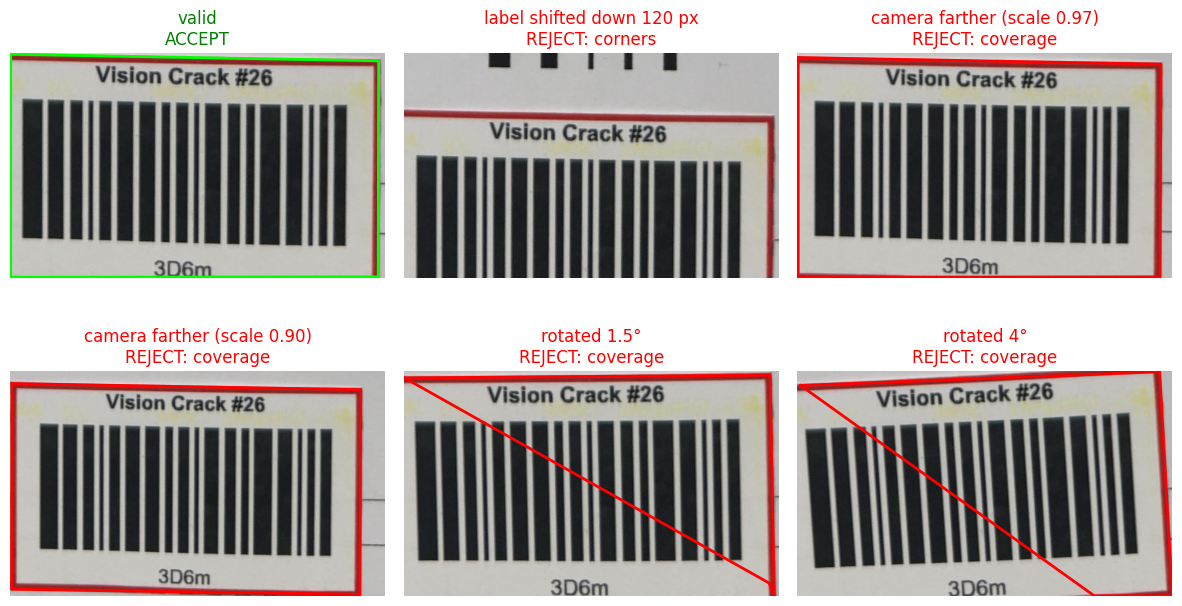

,case,result,top,right,bottom,left,angle_deg
0,valid,ACCEPT,0.981,0.960,0.980,0.992,0.00
1,label shifted down 120 px,REJECT: corners,NaN,NaN,NaN,NaN,NaN
2,camera farther (scale 0.97),REJECT: coverage,0.967,0.946,0.965,0.977,0.00
3,camera farther (scale 0.90),REJECT: coverage,0.930,0.910,0.928,0.914,-0.13
4,rotated 1.5°,REJECT: coverage,0.975,0.981,0.014,0.912,60.64
5,rotated 4°,REJECT: coverage,0.957,0.996,0.208,0.935,54.38


In [ ]:
img = vc.read_rgb(caps.path[0])
cx, cy = roi.x + roi.w / 2, roi.y + roi.h / 2
def warp(angle=0, scale=1, dy=0):
    M = cv2.getRotationMatrix2D((cx, cy), angle, scale); M[1, 2] += dy
    return cv2.warpAffine(img, M, (img.shape[1], img.shape[0]), borderValue=(255, 255, 255))

cases = [('valid', {}), ('label shifted down 120 px', dict(dy=120)),
         ('camera farther (scale 0.97)', dict(scale=.97)), ('camera farther (scale 0.90)', dict(scale=.90)),
         ('rotated 1.5°', dict(angle=1.5)), ('rotated 4°', dict(angle=4))]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.2)); rows = []
for ax, (name, kw) in zip(axes.ravel(), cases):
    w = warp(**kw); c, g = run_gates(w)
    ax.imshow(w[y0:y1, x0:x1]); ax.axis('off')
    if c is not None:
        q = c.as_array()[[0, 1, 3, 2, 0]]; ax.plot(q[:, 0], q[:, 1], 'lime' if g.accepted else 'red', lw=2)
    verdict = 'ACCEPT' if g.accepted else f'REJECT: {g.first_failure}'
    ax.set_title(f'{name}\n{verdict}', color='green' if g.accepted else 'red')
    rows.append({'case': name, 'result': verdict, **{k: round(v, 3) for k, v in g.ratios.items()},
                 'angle_deg': round(g.angle_deg, 2)})
fig.subplots_adjust(hspace=0.35, wspace=0.05); plt.savefig(FIG / 'fig_conditions.png', dpi=200, bbox_inches='tight'); plt.show()
pd.DataFrame(rows)

## 3 · Synthetic label geometry: which gate catches which pose?
Corner positions of a label that covers 95 % of an 828 × 495 px ROI at 0°, for in-plane rotation (0–5°),
pitch (0–10°) and yaw (0–10°). The coverage ratios are relative to the label size at 0° (`ref`).

In [ ]:
pp = json.load(open(io.repo_root() / 'data' / 'synthetic' / 'pose_points.json'))
def tl_tr_bl_br(d):   # file order is P1 TL, P2 TR, P3 BR, P4 BL
    return np.array([d['P1'], d['P2'], d['P4'], d['P3']], float)
ref = tl_tr_bl_br(pp['rotate']['0'])
REF_W, REF_H = ref[1, 0] - ref[0, 0], ref[2, 1] - ref[0, 1]
rows = []
for kind in ('rotate', 'pitch', 'yaw'):
    for deg, d in pp[kind].items():
        g = gates.evaluate(tl_tr_bl_br(d), REF_W, REF_H)   # coverage relative to the 0° label
        r = {k: v for k, v in g.ratios.items()}
        rows.append({'pose': kind, 'deg': int(deg), 'min_side_ratio': round(min(r.values()), 4),
                     'angle_deg': round(g.angle_deg, 2), 'coverage_ok': g.coverage_ok,
                     'rotation_ok': g.rotation_ok, 'accepted': g.accepted})
geo = pd.DataFrame(rows); geo.to_csv(TAB / 'gate_geometry.csv', index=False)
geo.pivot(index='deg', columns='pose', values='accepted')

pose,pitch,rotate,yaw
deg,,,
0,True,True,True
1,True,True,True
2,True,True,True
3,True,False,True
4,False,False,True
5,False,False,True
6,False,NaN,True
7,False,NaN,False
8,False,NaN,False


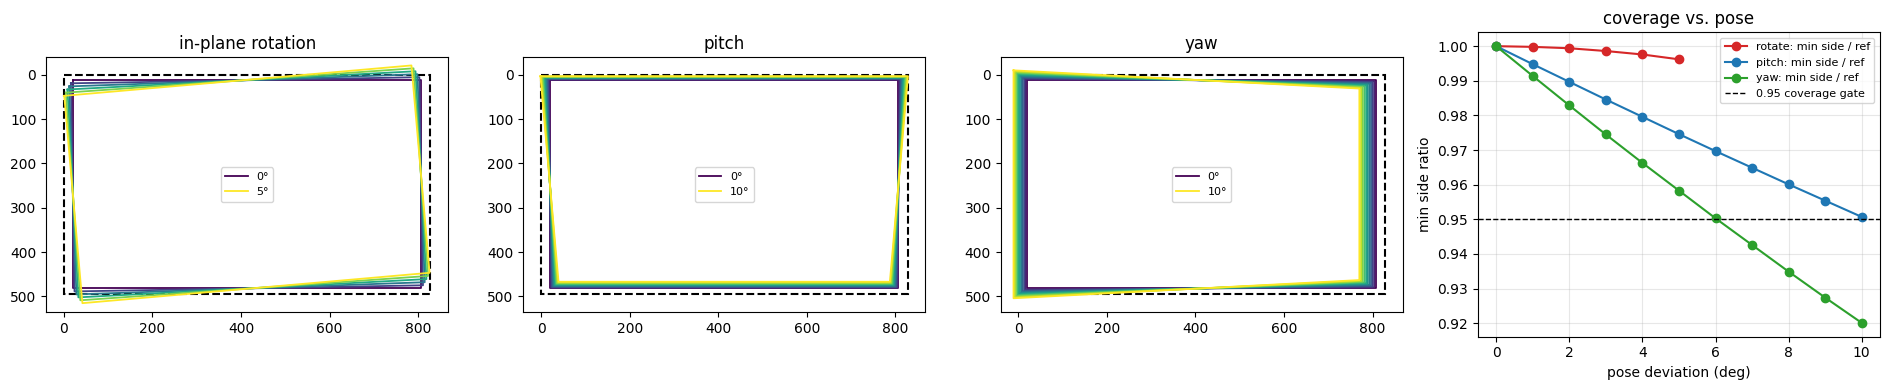

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, kind, title in zip(ax[:3], ('rotate', 'pitch', 'yaw'), ('in-plane rotation', 'pitch', 'yaw')):
    a.add_patch(plt.Rectangle((0, 0), *pp['roi_wh'], fill=False, ec='k', lw=1.5, ls='--'))
    degs = sorted(pp[kind], key=int)
    for i, deg in enumerate(degs):
        q = np.array([pp[kind][deg][k] for k in ('P1', 'P2', 'P3', 'P4', 'P1')])
        a.plot(q[:, 0], q[:, 1], color=plt.cm.viridis(i / max(1, len(degs) - 1)), lw=1.3, label=f'{deg}°' if i in (0, len(degs) - 1) else None)
    a.set_xlim(-40, pp['roi_wh'][0] + 40); a.set_ylim(pp['roi_wh'][1] + 40, -40); a.set_aspect('equal')
    a.set_title(title); a.legend(fontsize=8, loc='center')
for kind, col in [('rotate', 'C3'), ('pitch', 'C0'), ('yaw', 'C2')]:
    g = geo[geo.pose == kind]
    ax[3].plot(g.deg, g.min_side_ratio, 'o-', color=col, label=f'{kind}: min side / ref')
ax[3].axhline(0.95, color='k', ls='--', lw=1, label='0.95 coverage gate')
ax[3].set(xlabel='pose deviation (deg)', ylabel='min side ratio', title='coverage vs. pose')
ax[3].grid(alpha=.3); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'fig_gate_geometry.png', dpi=200); plt.show()

In [ ]:
for kind in ('rotate', 'pitch', 'yaw'):
    g = geo[geo.pose == kind]
    first = g[~g.accepted].deg.min()
    why = g[g.deg == first][['coverage_ok', 'rotation_ok']].to_dict('records')[0] if pd.notna(first) else {}
    print(f'{kind:6s}: first rejected at {first}°  {why}' if pd.notna(first) else f'{kind:6s}: never rejected up to {g.deg.max()}°')

rotate: first rejected at 3°  {'coverage_ok': True, 'rotation_ok': False}
pitch : first rejected at 4°  {'coverage_ok': True, 'rotation_ok': False}
yaw   : first rejected at 7°  {'coverage_ok': False, 'rotation_ok': True}


* **In-plane rotation** is caught by the rotation gate (from 2–3°).
* **Pitch** is also caught by the *rotation* gate: perspective turns the box into a trapezoid, so the left edge P1→P3
  slants. This is indirect protection; the gate was designed for in-plane rotation.
* **Yaw** is caught only by *coverage*, once the far side drops below 95 % (here ≈ 6–7°).

Below those angles out-of-plane tilt **passes all gates**. The scale error there is small (< 0.6 % at 6°, notebook 08),
but the gates do not measure tilt directly. That is the blind spot in the paper (Sec. *Geometric sensitivity*, R2.2).